# Red Cedar — Quick Start

This notebook is a quick way to get started with Red Cedar. It shows how to train a quantum machine learning model on a set of training data, and then apply that model to data whose class is unknown, inferring the class of each row and reporting on the results.

The steps:
1. Train a quantum model on a CSV file
2. Check the quality of the training
3. Infer the class of samples whose class is unknown
4. Verify the results
5. See which input features the model relies on

The data is the Wisconsin breast cancer dataset (WDBC). Each row is a tumor sample: 30 measurements (the *features*) and a diagnosis (the *class*), `M` for malignant or `B` for benign. The notebook uses two files in the `data/` folder next to it:
- `wdbc_train.csv`: 455 samples with their diagnosis, to train the model.
- `wdbc_unknown.csv`: 114 other samples, with the measurements only. Their diagnosis is unknown; the trained model infers it.

All computation happens on the server; this notebook sends requests and plots the results. The Quick Start page of the documentation shows the same workflow for your own data, and the [User Guide](https://coherent-computing.github.io/redcedar/user_guide/) describes every SDK function. To explore a dataset before training (PCA, mutual information, qubit estimates) see `02_dataset_analysis.ipynb`.

In [1]:
# The two data files described above
train_file = "data/wdbc_train.csv"       # 455 samples with their diagnosis, to train on
unknown_file = "data/wdbc_unknown.csv"   # 114 samples, measurements only: diagnosis unknown

In [2]:
import redcedar
import matplotlib.pyplot as plt

# Connect to a Red Cedar server: the one in REDCEDAR_URL (with the key in REDCEDAR_API_KEY)
# if those are set, otherwise the one on this machine, http://127.0.0.1:8002
client = redcedar.connect()
print(client.status())

# To choose a server in the code instead:
# client = redcedar.connect(url="https://your-server/api", api_key="your-key")

# Developers with the Red Cedar source installed (pip install -e) can use local mode,
# which runs Red Cedar in this process, with no server:
# client = redcedar.connect(local=True)

{'ok': True, 'server_version': '0.92-18-g1706a0dc-dirty', 'sdk_version': '0.93.0'}


## 1. Train a model

Training teaches a model to recognize patterns in data. You give Red Cedar a table in which every row has a set of features and a known class; the model learns which patterns of features go with which class, so that it can later infer the class of rows it has never seen.

The function `training.run()` takes the path of a CSV file: the SDK uploads it and the server trains the model on it. The last column is the class; a header row is optional.

**How the model works.** A Red Cedar model is a quantum circuit. The features of a row are encoded on the circuit's qubits, the circuit applies a series of quantum operations whose settings, the *parameters*, can be adjusted, and measuring the circuit gives the class. Training adjusts the parameters step by step; each step, a *parameter update*, is chosen to make the circuit more likely to give each training row its correct class (it lowers the training loss, shown in section 2).

**Layers.** The circuit is built in layers. Each layer adds another set of operations, and so more parameters, which lets the model capture more complex patterns. Red Cedar trains one layer at a time: first a model with one layer, then a model with two layers that starts from the parameters the first one found, and so on. Each finished layer is saved as a model of its own; more layers often, but not always, give a better accuracy.

**Settings.** `num_qubits` sets the size of the circuit, and `min_layers` and `max_layers` the layers to train. Here we use 6 qubits and 2 layers, which trains in about a minute. `seed` fixes the starting parameters, so the run can be repeated exactly. Every setting is listed in the [User Guide](https://coherent-computing.github.io/redcedar/user_guide/#settings).

At the end of each layer the server tests the model on rows it set aside from the file (20% by default), rows the model does not train on; those results come back in `result["validation"]`.

In [3]:
result = client.training.run(train_file, verbose=True, settings={
    "num_qubits": 6,
    "min_layers": 1,
    "max_layers": 2,
    "seed": 123,
})

train_id = result["train_id"]
print(f"\nModel ID: {train_id}")
print(f"Training time: {result['elapsed_seconds']}s")
for layer, v in result["validation"].items():
    print(f"Layer {layer}: test accuracy {v['test_accuracy']:.1%}, test loss {v['test_loss']:.4f}")

  [  5%] Layer 1/2 ...
  Layer 1: test accuracy 87.9%
  [ 50%] Layer 2/2 ..........
  Layer 2: test accuracy 87.9%
  [100%] Done.

Model ID: 810446ab-443e-42ed-9cea-a17dd2de60e3
Training time: 28.5s
Layer 1: test accuracy 87.9%, test loss 0.4675
Layer 2: test accuracy 87.9%, test loss 0.4760


## 2. Training quality

While the model trains, Red Cedar measures its loss and accuracy on the training rows after every parameter update, in each layer. These measurements come back with the result, in `result["history"]`, so you can see how the training progressed.

- **Training loss** says how far the model's answers are from the right ones. For each row the model gives a probability to every class; the loss is built from 1 minus the probability of the correct class, averaged over the training rows. It goes down as the model becomes more sure of the right answers.
- **Training accuracy** is the share of training rows whose correct class is the one the model finds most likely.

The test results printed above are the same two measures on the rows held back, which the model never trains on. The [User Guide](https://coherent-computing.github.io/redcedar/user_guide/#training-loss-and-accuracy) has the details.

The plots below show them, one curve per layer; the dashed line marks where a new layer starts. A falling loss and a rising accuracy show the model is learning, and a curve that levels off means that layer has gone as far as it can.

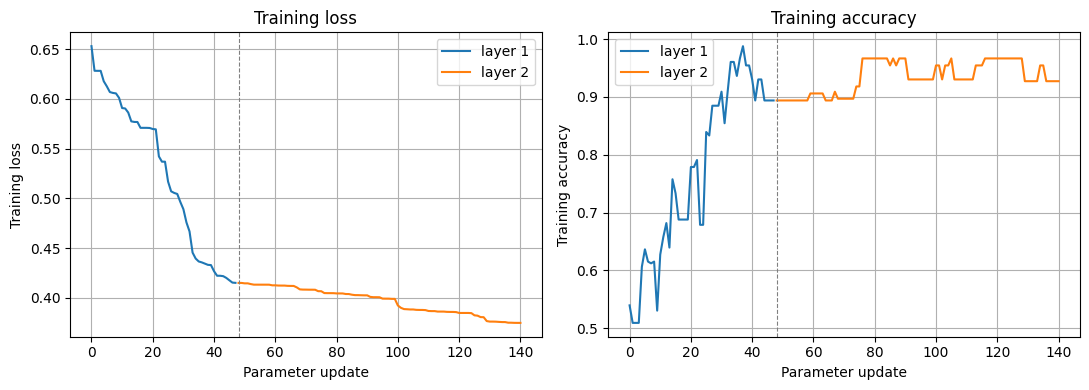

In [4]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))
start = 0
for layer, points in result["history"].items():
    steps = range(start, start + len(points))
    ax_loss.plot(steps, [p["train_loss"] for p in points], label=f"layer {layer}")
    ax_acc.plot(steps, [p["train_accuracy"] for p in points], label=f"layer {layer}")
    if start:
        ax_loss.axvline(start, color="gray", ls="--", lw=0.8)
        ax_acc.axvline(start, color="gray", ls="--", lw=0.8)
    start += len(points)

ax_loss.set(xlabel="Parameter update", ylabel="Training loss", title="Training loss")
ax_acc.set(xlabel="Parameter update", ylabel="Training accuracy", title="Training accuracy")
for ax in (ax_loss, ax_acc):
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

## 3. Infer the class of the unknown samples

Now we use the trained model on the 114 samples in `wdbc_unknown.csv`, whose diagnosis is unknown. For each one the model infers the class, malignant (`M`) or benign (`B`), with a confidence: the probability the model gives that class.

The function `inference.run()` takes the model's ID and the file of unknown samples, whose columns are matched to the training file's by name. `output=` writes each sample with its inferred class and the probability of each class to a CSV file, here `wdbc_unknown_inferred.csv` next to this notebook.

  [100%] Done.

Of the 114 unknown samples, the model infers 38 malignant (M) and 76 benign (B).

The first 10:
  Sample  Inferred        Confidence
       1  Malignant (M)   74%
       2  Malignant (M)   79%
       3  Malignant (M)   66%
       4  Malignant (M)   78%
       5  Benign (B)      70%
       6  Malignant (M)   79%
       7  Malignant (M)   74%
       8  Malignant (M)   65%
       9  Benign (B)      74%
      10  Malignant (M)   66%

Each sample with its inferred class and probabilities is written to wdbc_unknown_inferred.csv


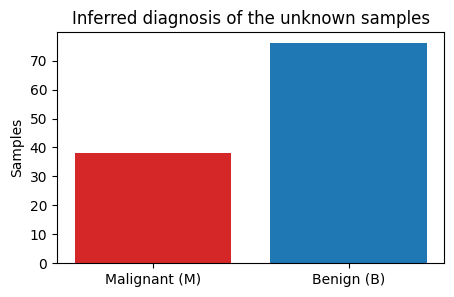

In [5]:
results = client.inference.run(train_id, unknown_file, output="wdbc_unknown_inferred.csv", verbose=True)
inferred = results["predictions"]

names = {"M": "Malignant (M)", "B": "Benign (B)"}
counts = {c: sum(str(r["prediction"]) == c for r in inferred) for c in names}
print(f"\nOf the {len(inferred)} unknown samples, the model infers {counts['M']} malignant (M) and {counts['B']} benign (B).")

print("\nThe first 10:")
print(f"  {'Sample':>6}  {'Inferred':<14}  Confidence")
for i, r in enumerate(inferred[:10], start=1):
    c = str(r["prediction"])
    print(f"  {i:>6}  {names[c]:<14}  {r['probabilities'][c]:.0%}")
print("\nEach sample with its inferred class and probabilities is written to wdbc_unknown_inferred.csv")

plt.figure(figsize=(5, 3))
plt.bar([names[c] for c in counts], list(counts.values()), color=["tab:red", "tab:blue"])
plt.ylabel("Samples")
plt.title("Inferred diagnosis of the unknown samples")
plt.show()

## 4. Verify the results

To see how well the quantum model does, we compare its inferences with the true diagnoses of the 114 unknown samples. Because the samples come from a public dataset, their true diagnoses are known. They are in `data/wdbc_unknown_true_diagnosis.csv`, which the model never sees. With your own unknown data there would be no such file: this check is possible here only because the answers are known.

This is a different check from the test results in section 1. Those come from rows the server set aside from the training file; this one uses a separate file of samples, the way a trained model is used in practice.

In [6]:
import csv
with open("data/wdbc_unknown_true_diagnosis.csv", newline="") as f:
    true_diagnosis = [row["diagnosis"] for row in csv.DictReader(f)]

correct = sum(str(r["prediction"]) == t for r, t in zip(inferred, true_diagnosis))
print(f"{correct} of {len(true_diagnosis)} inferred correctly ({correct / len(true_diagnosis):.1%})")
for c in names:
    right = sum(str(r["prediction"]) == t == c for r, t in zip(inferred, true_diagnosis))
    print(f"  {names[c]}: {right} of {true_diagnosis.count(c)} inferred correctly")

98 of 114 inferred correctly (86.0%)
  Malignant (M): 32 of 42 inferred correctly
  Benign (B): 66 of 72 inferred correctly


## 5. Which features the model relies on

Explainable AI maps each data qubit back to the input feature it encodes and measures how much that qubit influences the prediction.

  [100%] Done.
  Qubit 0: mean_radius (importance 76.3%)
  Qubit 1: mean_radius (importance 3.7%)
  Qubit 2: worst_concave_points (importance 14.3%)
  Qubit 3: mean_perimeter (importance 38.1%)
  Qubit 4: worst_compactness (importance 0.0%)


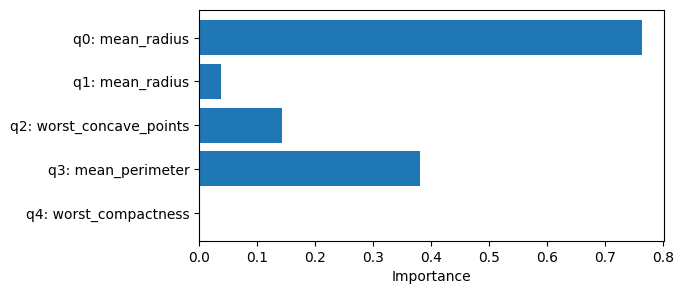

In [7]:
explanation = client.explainable.run(train_id, verbose=True)

qubits = explanation["qubit_map"]
for q in qubits:
    print(f"  Qubit {q['qubit']}: {q['feature_name']} (importance {q['importance']:.1%})")

plt.figure(figsize=(6, 3))
plt.barh([f"q{q['qubit']}: {q['feature_name']}" for q in qubits], [q["importance"] for q in qubits])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.show()

## Next steps

- `02_dataset_analysis.ipynb`: explore a dataset before training, or analyze your own CSV file
- `03_training_settings.ipynb`: settings you can change, one section per setting
- `04_training_in_depth.ipynb`: layers, testing on the rows the server set aside (`training.evaluate()`), test accuracy over the course of training, choosing the data, reusing models, stopping a job